# **Notebook 6: Fine-Tuning Pipeline**
## Assignment: Hybrid RAG & Fine-Tuning for Customer Support
---

### TO-DO: Before Running This Notebook

**Files you NEED:**
- [ ] `./tokenized_train/` + `./tokenized_valid/` — Created by Notebook 2
- [ ] GPU runtime enabled (T4 minimum)

**Files this notebook will CREATE:**
- [ ] `./intent_lora_best/` — Best LoRA checkpoint (by val loss) _(Required by NB7)_
- [ ] `./intent_lora/` — Final LoRA checkpoint _(Backup)_
- [ ] `training_log.csv` + `training_curves.png` — Evidence for report

---

## **Stage 4: Solution V2 (Fine-Tuned Retrieval-Assisted Generation)**

### **Task 4.1: Configure Fine-Tuning Pipeline**

#### **4.1.1 Configure PEFT Framework [3 marks]**
**The Task:** Apply LoRA (or QLoRA) to the model's `q_proj` and `v_proj` attention modules, set adapter settings and target modules, and prepare the training environment.

**Hints & Tips:**
* LoRA adds small trainable matrices to frozen attention layers — only ~0.5–1% of params update.
* `r=16` = rank of the low-rank matrices; `lora_alpha=32` scales them (rule of thumb: alpha = 2×r).
* `target_modules=["q_proj","v_proj"]`. Adding `["k_proj","o_proj"]` trains more params but may overfit on small data.
* Call `peft_model.print_trainable_parameters()` to confirm the tiny trainable %.

**LoRA Config Tuning:**
* `r`: 8 (lighter), **16 (recommended)**, 32 (more capacity).
* `lora_alpha`: usually 2×r → 16, **32**, 64.

**Learner Inference:** Updating only attention projections fundamentally changes behaviour (chat → JSON) using a fraction of the compute.

In [1]:
%pip install -q -U bitsandbytes peft accelerate datasets

import os, json, time, random
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
from transformers import AutoTokenizer, AutoModelForCausalLM, BitsAndBytesConfig, get_linear_schedule_with_warmup
from peft import LoraConfig, get_peft_model, prepare_model_for_kbit_training
import peft, transformers

from google.colab import drive
if not os.path.isdir('/content/drive/MyDrive'):
    drive.mount('/content/drive')
os.chdir('/content/drive/MyDrive/hybrid_rag')

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
torch.cuda.manual_seed_all(SEED)

with open('router_config.json') as f:
    router_config = json.load(f)
MODEL_ID = router_config['model_id']
assert torch.cuda.is_available(), 'switch the runtime to a T4 GPU'
DEVICE = 'cuda'

# QLoRA: the base model stays frozen in 4-bit, only the small LoRA matrices are trained
bnb_config = BitsAndBytesConfig(load_in_4bit=True, bnb_4bit_quant_type='nf4',
                                bnb_4bit_use_double_quant=True, bnb_4bit_compute_dtype=torch.float16)
tokenizer = AutoTokenizer.from_pretrained(MODEL_ID)
model = AutoModelForCausalLM.from_pretrained(MODEL_ID, quantization_config=bnb_config, device_map={'': 0})
model.config.use_cache = False
model = prepare_model_for_kbit_training(model, use_gradient_checkpointing=True,
                                        gradient_checkpointing_kwargs={'use_reentrant': False})

lora_config = LoraConfig(
    r=16,
    lora_alpha=32,
    lora_dropout=0.05,
    target_modules=['q_proj', 'v_proj'],
    bias='none',
    task_type='CAUSAL_LM',
)
peft_model = get_peft_model(model, lora_config)
peft_model.print_trainable_parameters()

print(torch.cuda.get_device_name(0), '| torch', torch.__version__, '| transformers', transformers.__version__, '| peft', peft.__version__)
print(f'GPU memory used: {torch.cuda.memory_allocated() / 1e9:.2f} GB')

/usr/local/lib/python3.13/dist-packages/huggingface_hub/utils/_auth.py:138: UserWarning: 
Error while fetching `HF_TOKEN` secret value from your vault: 'Requesting secret HF_TOKEN timed out. Secrets can only be fetched when running from the Colab UI.'.
  warnings.warn(f"\nError while fetching `HF_TOKEN` secret value from your vault: '{str(e)}'.")


Loading weights:   0%|          | 0/338 [00:00<?, ?it/s]

trainable params: 2,179,072 || all params: 1,545,893,376 || trainable%: 0.1410
Tesla T4 | torch 2.11.0+cu130 | transformers 5.18.0 | peft 0.21.2
GPU memory used: 1.63 GB


#### **4.1.2 Configure Training Parameters [2 marks]**
**The Task:** Define the learning rate, batch size, number of steps/epochs, optimisation strategy (AdamW), and quantisation settings.

**Hints & Tips:**
* Initialise `AdamW(filter(lambda p: p.requires_grad, peft_model.parameters()), lr=2e-4)`.
* Build `DataLoader`s for the train and validation sets (remember `set_format("torch", ...)` after `load_from_disk`).
* Define `VAL_EVERY` (e.g. 10 steps) and an early-stopping `PATIENCE` (e.g. 3) for the next task.

**Parameter Tuning:**
* `lr=2e-4` standard; try `1e-4` (slower) or `5e-4` (faster).
* `batch_size=4` fits T4; use 2 if OOM, 8 on A100.
* `max_steps=200`: ~25% of one epoch on 3200 rows. Increase to 400–500 for a full epoch.

**Learner Inference:** These hyperparameters control how fast and how stably the adapter learns the JSON-extraction task.

In [2]:
from datasets import load_from_disk
from torch.utils.data import DataLoader
from torch.optim import AdamW

COLS = ['input_ids', 'attention_mask', 'labels']
train_ds = load_from_disk('tokenized_train')
valid_ds = load_from_disk('tokenized_valid')
train_ds.set_format('torch', columns=COLS)
valid_ds.set_format('torch', columns=COLS)
print(len(train_ds), 'train rows,', len(valid_ds), 'validation rows')

BATCH_SIZE = 4
EVAL_BATCH_SIZE = 8
LR = 2e-4
WEIGHT_DECAY = 0.01
NUM_EPOCHS = 1
WARMUP_STEPS = 20
GRAD_CLIP = 1.0
VAL_EVERY = 25
PATIENCE = 3
MIN_DELTA = 1e-4

g = torch.Generator().manual_seed(SEED)
train_loader = DataLoader(train_ds, batch_size=BATCH_SIZE, shuffle=True, generator=g)
valid_loader = DataLoader(valid_ds, batch_size=EVAL_BATCH_SIZE)
MAX_STEPS = len(train_loader) * NUM_EPOCHS

optimizer = AdamW(filter(lambda p: p.requires_grad, peft_model.parameters()), lr=LR, weight_decay=WEIGHT_DECAY)
scheduler = get_linear_schedule_with_warmup(optimizer, WARMUP_STEPS, MAX_STEPS)

train_config = {
    'model_id': MODEL_ID, 'quantisation': '4-bit nf4, double quant, fp16 compute',
    'lora_r': lora_config.r, 'lora_alpha': lora_config.lora_alpha, 'lora_dropout': lora_config.lora_dropout,
    'target_modules': sorted(lora_config.target_modules), 'optimizer': 'AdamW', 'lr': LR,
    'weight_decay': WEIGHT_DECAY, 'warmup_steps': WARMUP_STEPS, 'batch_size': BATCH_SIZE, 'epochs': NUM_EPOCHS,
    'max_steps': MAX_STEPS, 'val_every': VAL_EVERY, 'patience': PATIENCE, 'seed': SEED,
}
print(json.dumps(train_config, indent=2))

3116 train rows, 390 validation rows
{
  "model_id": "Qwen/Qwen2.5-1.5B-Instruct",
  "quantisation": "4-bit nf4, double quant, fp16 compute",
  "lora_r": 16,
  "lora_alpha": 32,
  "lora_dropout": 0.05,
  "target_modules": [
    "q_proj",
    "v_proj"
  ],
  "optimizer": "AdamW",
  "lr": 0.0002,
  "weight_decay": 0.01,
  "warmup_steps": 20,
  "batch_size": 4,
  "epochs": 1,
  "max_steps": 779,
  "val_every": 25,
  "patience": 3,
  "seed": 42
}


### **Task 4.2: Train Fine-Tuned Model**

#### **4.2.1 Execute Fine-Tuning [5 marks]**
**The Task:** Run the custom PyTorch training loop. Monitor BOTH train and validation loss at regular intervals, implement early stopping based on validation loss, and plot the train-vs-validation loss curves.

**Hints & Tips:**
* The validation loop runs every `VAL_EVERY` steps under `torch.no_grad()` (no gradients).
* Early stopping: track `best_val_loss`; if it doesn't improve for `PATIENCE` checks, stop.
* The loss-curve plot is mandatory evidence — save it as `training_curves.png`.

**What to look for in the curve:**
* Both lines falling → learning, no overfitting.
* Val rises while train falls → overfitting (early stopping saves you).
* Both flat → LR too low or data too small.
* Val spikes → bad batch / instability.

**Learner Inference:** Falling loss proves gradient descent is teaching the JSON format. Validation monitoring prevents silent memorisation.

In [3]:
BEST_DIR, FINAL_DIR = 'intent_lora_best', 'intent_lora'

def trim(batch):
    # everything is padded to 384 but real sequences are ~330 tokens, so drop the padding-only tail
    L = int(batch['attention_mask'].sum(1).max())
    return {k: v[:, :L].to(DEVICE) for k, v in batch.items()}

@torch.no_grad()
def evaluate():
    peft_model.eval()
    total, n_tokens = 0.0, 0
    for batch in valid_loader:
        b = trim(batch)
        n = (b['labels'][:, 1:] != -100).sum().item()
        total += peft_model(**b).loss.item() * n
        n_tokens += n
    peft_model.train()
    return total / n_tokens

log = [{'step': 0, 'train_loss': np.nan, 'val_loss': evaluate(), 'lr': 0.0, 'elapsed_s': 0.0}]
best_val, best_step, bad_checks = log[0]['val_loss'], 0, 0
print(f'step 0: val {best_val:.4f}')

peft_model.train()
step, running, stopped_early = 0, [], False
t0 = time.time()
while step < MAX_STEPS and not stopped_early:
    for batch in train_loader:
        loss = peft_model(**trim(batch)).loss
        loss.backward()
        torch.nn.utils.clip_grad_norm_(peft_model.parameters(), GRAD_CLIP)
        optimizer.step()
        scheduler.step()
        optimizer.zero_grad(set_to_none=True)
        step += 1
        running.append(loss.item())

        if step % VAL_EVERY == 0 or step == MAX_STEPS:
            val_loss = evaluate()
            log.append({'step': step, 'train_loss': np.mean(running), 'val_loss': val_loss,
                        'lr': scheduler.get_last_lr()[0], 'elapsed_s': round(time.time() - t0, 1)})
            running = []
            if val_loss < best_val - MIN_DELTA:
                best_val, best_step, bad_checks = val_loss, step, 0
                peft_model.save_pretrained(BEST_DIR)
                note = 'saved best'
            else:
                bad_checks += 1
                note = f'no improvement {bad_checks}/{PATIENCE}'
            print(f'step {step}: train {log[-1]["train_loss"]:.4f}, val {val_loss:.4f} ({note})')
            if bad_checks >= PATIENCE:
                stopped_early = True
                print('early stopping')
                break
        if step >= MAX_STEPS:
            break

train_time = time.time() - t0
if not os.path.isdir(BEST_DIR):
    peft_model.save_pretrained(BEST_DIR)
log_df = pd.DataFrame(log)
print(f'{step} steps in {train_time / 60:.1f} min, best val loss {best_val:.4f} at step {best_step}')

step 0: val 0.1002


step 25: train 0.0682, val 0.0496 (saved best)


step 50: train 0.0285, val 0.0275 (saved best)


step 75: train 0.0118, val 0.0234 (saved best)


step 100: train 0.0223, val 0.0236 (no improvement 1/3)


...

step 200: train 0.0095, val 0.0075 (saved best)


step 225: train 0.0021, val 0.0066 (saved best)


step 250: train 0.0078, val 0.0071 (no improvement 1/3)


step 275: train 0.0043, val 0.0171 (no improvement 2/3)


step 300: train 0.0103, val 0.0072 (no improvement 3/3)
early stopping
300 steps in 16.2 min, best val loss 0.0066 at step 225


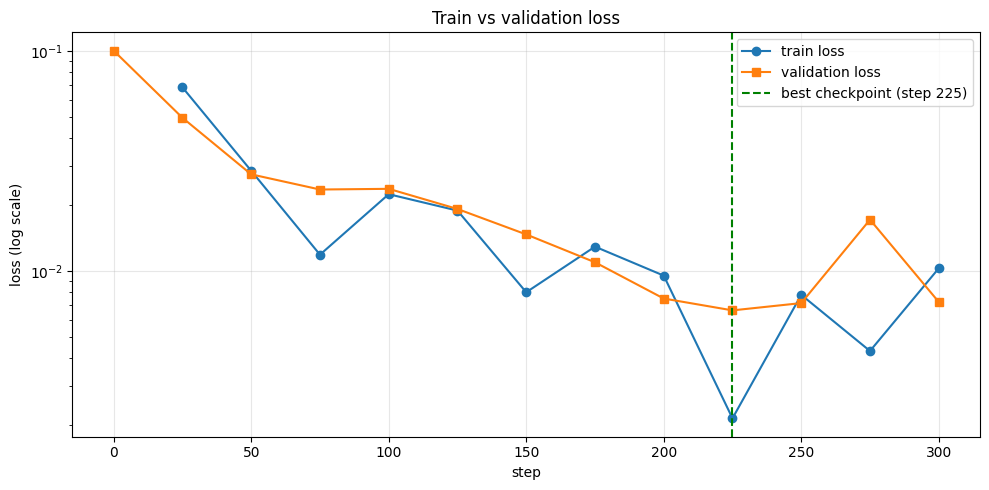

,step,train_loss,val_loss,lr,elapsed_s
0,0,NaN,0.1002,0.0000,0.0
1,25,0.0682,0.0496,0.0002,79.7
2,50,0.0285,0.0275,0.0002,161.1
3,75,0.0118,0.0234,0.0002,242.5
4,100,0.0223,0.0236,0.0002,324.1
5,125,0.0188,0.0191,0.0002,405.3
6,150,0.0080,0.0146,0.0002,486.9
7,175,0.0129,0.0109,0.0002,568.6
8,200,0.0095,0.0075,0.0002,649.8
9,225,0.0021,0.0066,0.0001,731.0


In [4]:
fig, ax = plt.subplots(figsize=(10, 5))
ax.plot(log_df['step'], log_df['train_loss'], marker='o', label='train loss')
ax.plot(log_df['step'], log_df['val_loss'], marker='s', label='validation loss')
ax.axvline(best_step, color='green', ls='--', label=f'best checkpoint (step {best_step})')
ax.set(title='Train vs validation loss', xlabel='step', ylabel='loss (log scale)')
ax.set_yscale('log')
ax.legend()
ax.grid(alpha=0.3)
plt.tight_layout()
plt.savefig('training_curves.png', dpi=120)
plt.show()
display(log_df.round(4))

#### **4.2.2 Save Training Outputs [2 marks]**
**The Task:** Save the best checkpoint (by validation loss), document the checkpoint/model-saving workflow, and export reproducibility information.

**Hints & Tips:**
* Save two checkpoints: `./intent_lora_best/` (lowest val loss) and `./intent_lora/` (final step).
* Export a `training_log.csv` with columns `step, train_loss, val_loss`.
* Record reproducibility info: model ID, LoRA config, learning rate, batch size, seed.

**Learner Inference:** Saving the BEST checkpoint (not the last) ensures your final model is the one that generalised best, not one that started overfitting.

In [5]:
# intent_lora_best/ was written during training every time val loss improved; intent_lora/ is the last step
peft_model.save_pretrained(FINAL_DIR)
tokenizer.save_pretrained(BEST_DIR)
tokenizer.save_pretrained(FINAL_DIR)
log_df.to_csv('training_log.csv', index=False)

run_info = {**train_config, 'steps_run': step, 'early_stopped': stopped_early, 'best_step': best_step,
            'best_val_loss': best_val, 'train_minutes': round(train_time / 60, 1),
            'gpu': torch.cuda.get_device_name(0), 'torch': torch.__version__,
            'transformers': transformers.__version__, 'peft': peft.__version__}
with open('training_config.json', 'w') as f:
    json.dump(run_info, f, indent=2)

for d in [BEST_DIR, FINAL_DIR]:
    print(d, sorted(os.listdir(d)))

intent_lora_best ['README.md', 'adapter_config.json', 'adapter_model.safetensors', 'chat_template.jinja', 'tokenizer.json', 'tokenizer_config.json']
intent_lora ['README.md', 'adapter_config.json', 'adapter_model.safetensors', 'chat_template.jinja', 'tokenizer.json', 'tokenizer_config.json']


---
## END-OF-NOTEBOOK CHECKLIST

> **IMPORTANT: Verify before proceeding to Notebook 7.**

- [ ] Tokenized train/valid loaded from disk (`set_format` re-applied)
- [ ] **4.1.1** LoRA configured targeting `q_proj`/`v_proj`
- [ ] **4.1.2** Optimizer + training params + dataloaders set
- [ ] **4.2.1** Training loop run with val monitoring + early stopping + loss curve
- [ ] **4.2.2** Best checkpoint saved + reproducibility info recorded
- [ ] **`./intent_lora_best/` saved** ← _CRITICAL for NB7_
- [ ] **`training_log.csv` + `training_curves.png` saved** ← _Evidence_

**If any item is unchecked, fix it before moving on.**